# DS2002 · Midterm Clinic Analysis and Charts

**Studio — 2026-10-28 · Fall 2026**  
**Class time:** 45 minutes

---

## Clinic — analysis and charts

Working session on your own project. The patterns below are the four analytical moves Questions 1 through 4 need; adapt each one to your cleaned data.

By the end of the hour you should have at least two charts you would be willing to put in the presentation on Monday.

### Pattern 1 — products moving together before landfall

One line per product, landfall marked. This is the Q1 chart, and it is the one that carries your presentation.

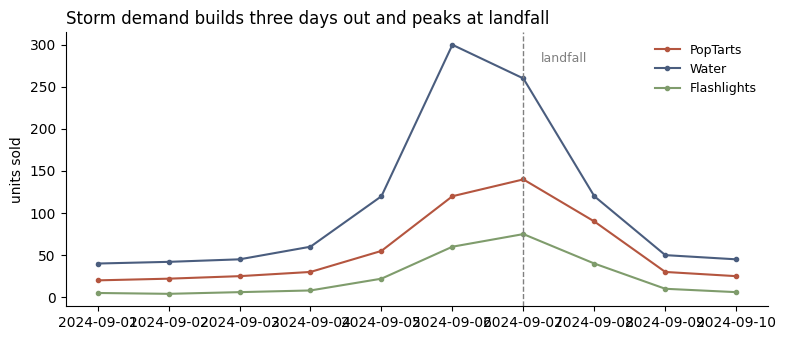

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

daily = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=10),
    'PopTarts': [20, 22, 25, 30, 55, 120, 140, 90, 30, 25],
    'Water': [40, 42, 45, 60, 120, 300, 260, 120, 50, 45],
    'Flashlights': [5, 4, 6, 8, 22, 60, 75, 40, 10, 6],
}).set_index('date')
landfall = pd.Timestamp('2024-09-07')

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(daily.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall + pd.Timedelta(hours=6), 280),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds three days out and peaks at landfall',
             loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** rebuild that with your own cleaned categories and your own landfall date. Title it with what your data actually shows — if your surge peaks a day early, say that.

25,562 raw rows -> 25,532 clean | 45 SKUs -> 20 products
dates: 2024-09-01 to 2024-09-30


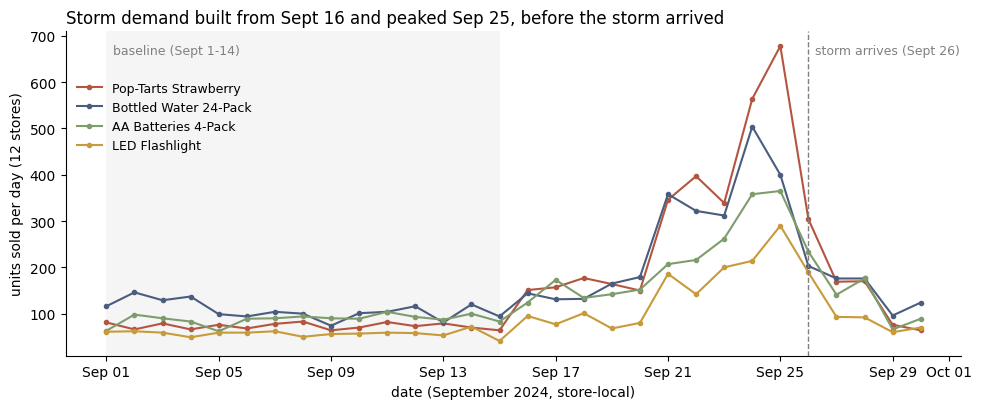

peak day for these four products: 2024-09-25


In [2]:
# Setup: load and clean our team's data (same steps as team_notebook.ipynb, sections 1-2.2, condensed)
import pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.dates as mdates
BASE = ('https://raw.githubusercontent.com/aymanr8-dot/DS-2002-Walmart-Hurricane-Project_Data-Demons-/main/data/')
raw = pd.read_csv(BASE + 'walmart_transactions.csv', dtype=str)
stores = pd.read_csv(BASE + 'store_locations.csv', dtype=str)

def clean_store_id(s):
    s = s.astype(str).str.strip().str.upper().str.replace(r'[^A-Z0-9]', '', regex=True)
    return s.str.replace(r'^([A-Z]{2})(\d+)$', r'\1-\2', regex=True)

sales = raw.drop_duplicates().copy()
sales['store_id'] = clean_store_id(sales['store_id'])
sales['quantity'] = pd.to_numeric(sales['quantity']).astype(int)
ts = sales['timestamp'].str.strip()
parsed = pd.Series(pd.NaT, index=sales.index, dtype='datetime64[ns]')
for fmt in ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%m/%d/%Y %H:%M', '%m-%d-%Y %H:%M:%S', '%d-%b-%Y %H:%M']:
    parsed = parsed.fillna(pd.to_datetime(ts, format=fmt, errors='coerce'))
sales['date'] = parsed.dt.normalize()

# SKU -> product: link SKUs that cashiers sold under the same product name (union-find), then name each group
CANONICAL = {'PT-12': 'Pop-Tarts Strawberry', 'WTR-24': 'Bottled Water 24-Pack', 'BATT-100': 'AA Batteries 4-Pack',
             'FLASH-01': 'LED Flashlight', 'BEER-24': 'Light Beer 24-Pack', 'BG-MONO': 'Monopoly Board Game',
             'CARDS-01': 'Playing Cards', 'STREAM-01': 'Roku Streaming Stick', 'SOUP-CAN': 'Canned Soup',
             'BREAD-WH': 'White Bread', 'PB-16': 'Peanut Butter 16oz', 'CNDL-EM': 'Emergency Candles',
             'FAID-01': 'First Aid Kit', 'CHRG-PORT': 'Portable Phone Charger', 'CHIPS-VP': 'Chips Variety Pack',
             'PTOWEL-6': 'Paper Towels 6-Roll', 'TP-12': 'Toilet Paper 12-Roll', 'DIAP-S3': 'Diapers Size 3',
             'BFORM-01': 'Infant Formula', 'TARP-HD': 'Heavy Duty Tarp'}
sales['sku'] = sales['sku'].str.strip().str.upper()
pairs = pd.DataFrame({'sku': sales['sku'],
                      'name': sales['product_name'].str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)}).drop_duplicates()
parent = {}
def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
for s, n in pairs.itertuples(index=False):
    a, b = find('S:' + s), find('N:' + n)
    if a != b: parent[a] = b
groups = {}
for s in sorted(set(pairs['sku'])):
    groups.setdefault(find('S:' + s), []).append(s)
SKU_MAP = {}
for members in groups.values():
    keys = [s for s in members if s in CANONICAL]
    assert len(keys) == 1, members
    SKU_MAP.update({s: CANONICAL[keys[0]] for s in members})
sales['product'] = sales['sku'].map(SKU_MAP)
assert sales['product'].notna().all()

# Demand view: returns excluded, rows with no timestamp left out of anything by date
dated = sales[(sales['quantity'] > 0) & sales['date'].notna()]
BASELINE_START, BASELINE_END = pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-14')
SURGE_START, SURGE_END = pd.Timestamp('2024-09-16'), pd.Timestamp('2024-09-26')
LANDFALL = pd.Timestamp('2024-09-26')   # storm arrival = peak store-average gust in Open-Meteo data (team notebook 3.2)
daily = dated.groupby(['date', 'product'])['quantity'].sum().unstack().fillna(0)
print(f'{len(raw):,} raw rows -> {len(sales):,} clean | {sales["sku"].nunique()} SKUs -> {sales["product"].nunique()} products')
print('dates:', daily.index.min().date(), 'to', daily.index.max().date())

# Pattern 1 with our data: top movers, one line each, baseline shaded, storm arrival marked
TOP = ['Pop-Tarts Strawberry', 'Bottled Water 24-Pack', 'AA Batteries 4-Pack', 'LED Flashlight']
COLORS = ['#b4553f', '#4a5d7e', '#7f9c6c', '#c79a3a']
peak_day = daily[TOP].sum(axis=1).idxmax()
fig, ax = plt.subplots(figsize=(10, 4.2))
for col, color in zip(TOP, COLORS):
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)
ax.axvspan(BASELINE_START, BASELINE_END + pd.Timedelta(days=1), color='gray', alpha=0.08, lw=0)
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
ymax = ax.get_ylim()[1]
ax.annotate('storm arrives (Sept 26)', xy=(LANDFALL + pd.Timedelta(hours=6), ymax * 0.93), fontsize=9, color='gray')
ax.annotate('baseline (Sept 1-14)', xy=(BASELINE_START + pd.Timedelta(hours=6), ymax * 0.93), fontsize=9, color='gray')
ax.set_title(f'Storm demand built from Sept 16 and peaked {peak_day:%b %d}, before the storm arrived', loc='left', fontsize=12)
ax.set_ylabel('units sold per day (12 stores)')
ax.set_xlabel('date (September 2024, store-local)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(0, 0.88))
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()
print('peak day for these four products:', peak_day.date())


### Pattern 2 — indexing to baseline so different products are comparable

Water outsells flashlights ten to one, so on a raw chart the flashlight surge is invisible. Divide each series by its own pre-storm average and every product starts at 1.0 — now you are comparing *how much each one moved*, which is the actual question.

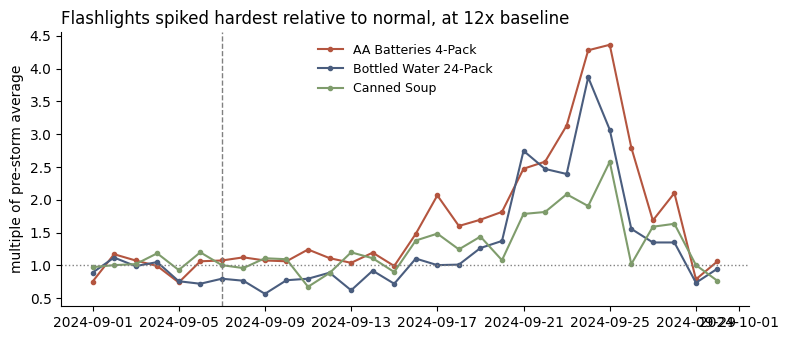

product
Pop-Tarts Strawberry      9.0
Heavy Duty Tarp           5.0
LED Flashlight            4.8
AA Batteries 4-Pack       4.4
Emergency Candles         4.4
Monopoly Board Game       4.1
Bottled Water 24-Pack     3.9
Portable Phone Charger    3.9
Roku Streaming Stick      3.8
Paper Towels 6-Roll       3.5
Toilet Paper 12-Roll      3.3
First Aid Kit             3.3
Light Beer 24-Pack        3.0
Playing Cards             3.0
Canned Soup               2.6
Peanut Butter 16oz        2.3
White Bread               2.2
Infant Formula            2.1
Diapers Size 3            2.0
Chips Variety Pack        1.5
dtype: float64


In [3]:
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()
indexed = daily / baseline

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(indexed.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.set_title('Flashlights spiked hardest relative to normal, at 12x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(indexed.max().round(1).sort_values(ascending=False))

Two charts, same data, different findings. The raw chart says water is the story; the indexed chart says flashlights are. Both belong in the presentation, in that order.

**TODO:** index your own products to their baseline and see whether your ranking changes.

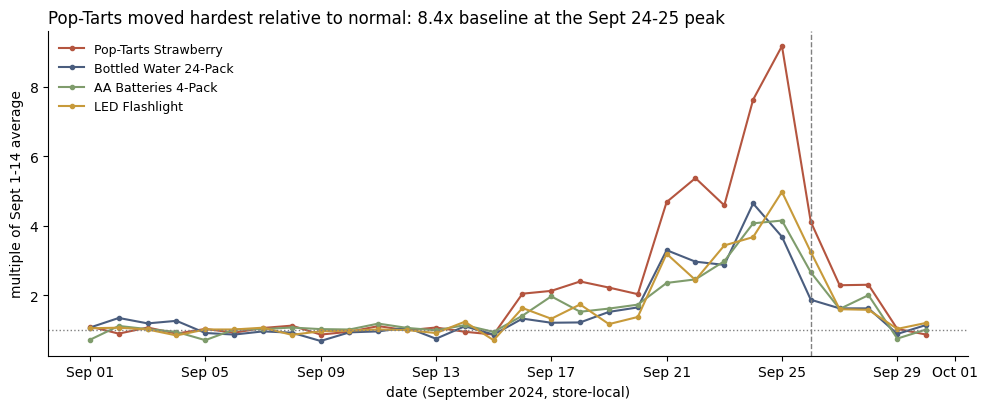

                        raw units/day in surge  \
product                                          
Pop-Tarts Strawberry                     312.0   
LED Flashlight                           149.0   
Heavy Duty Tarp                          111.0   
AA Batteries 4-Pack                      215.0   
Bottled Water 24-Pack                    259.0   
Monopoly Board Game                       97.0   
Portable Phone Charger                    94.0   
Emergency Candles                        126.0   

                        surge window multiple (Sept 16-26)  \
product                                                      
Pop-Tarts Strawberry                                  4.21   
LED Flashlight                                        2.56   
Heavy Duty Tarp                                       2.49   
AA Batteries 4-Pack                                   2.45   
Bottled Water 24-Pack                                 2.38   
Monopoly Board Game                                   2.23   
Por

In [4]:
# Pattern 2: index every product to its own Sept 1-14 average, then compare how far each one moved
baseline = daily.loc[BASELINE_START:BASELINE_END].mean()
indexed = daily / baseline
window_multiple = daily.loc[SURGE_START:SURGE_END].mean() / baseline       # Sept 16-26 vs baseline
peak_multiple = daily.loc['2024-09-24':'2024-09-25'].mean() / baseline     # Sept 24-25 peak vs baseline

fig, ax = plt.subplots(figsize=(10, 4.2))
for col, color in zip(TOP, COLORS):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
ax.set_title(f'Pop-Tarts moved hardest relative to normal: {peak_multiple["Pop-Tarts Strawberry"]:.1f}x baseline at the Sept 24-25 peak',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of Sept 1-14 average')
ax.set_xlabel('date (September 2024, store-local)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.legend(frameon=False, fontsize=9, loc='upper left')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

ranks = pd.DataFrame({'raw units/day in surge': daily.loc[SURGE_START:SURGE_END].mean().round(0),
                      'surge window multiple (Sept 16-26)': window_multiple.round(2),
                      'peak multiple (Sept 24-25)': peak_multiple.round(2)})
print(ranks.sort_values('surge window multiple (Sept 16-26)', ascending=False).head(8))
raw_rank = ranks['raw units/day in surge'].rank(ascending=False).astype(int)
idx_rank = ranks['surge window multiple (Sept 16-26)'].rank(ascending=False).astype(int)
print('\nRank changes, raw -> indexed:', {p: f'#{raw_rank[p]} -> #{idx_rank[p]}' for p in TOP})
print('Raw ranking leader:', ranks['raw units/day in surge'].idxmax(),
      '| indexed ranking leader:', ranks['surge window multiple (Sept 16-26)'].idxmax())


### Pattern 3 — before-and-after for Q2

The SKU consolidation question needs a comparison, not a description. Show the number somebody would have reported without your work next to the number with it.

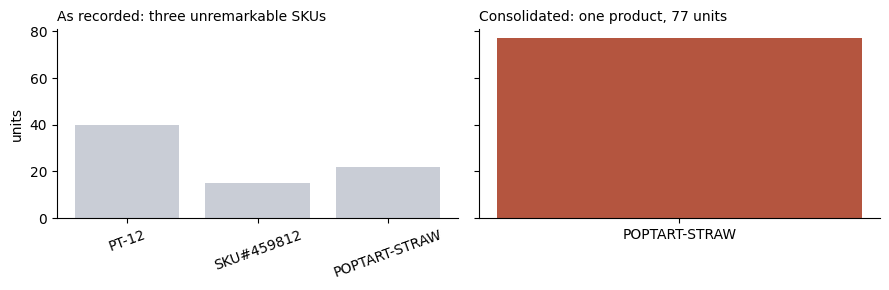

In [5]:
fragmented = pd.Series({'PT-12': 40, 'SKU#459812': 15, 'POPTART-STRAW': 22})
consolidated = pd.Series({'POPTART-STRAW': 77})

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title('As recorded: three unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title('Consolidated: one product, 77 units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** build this for your largest consolidated product family. State the multiple.

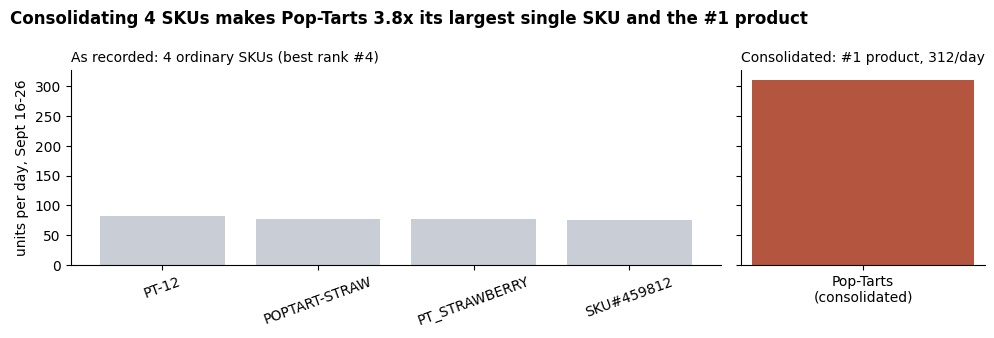

sku
PT-12            81.5
POPTART-STRAW    76.9
PT_STRAWBERRY    76.9
SKU#459812       76.2
consolidated: 311.5/day = 3.8x the largest SKU; top SKU overall is WTR_24PK (Bottled Water 24-Pack) at 91.5/day


In [6]:
# Pattern 3: Pop-Tarts before and after SKU consolidation, units/day in the Sept 16-26 surge window
n_days = (SURGE_END - SURGE_START).days + 1
surge = dated[dated['date'].between(SURGE_START, SURGE_END)]
pt = 'Pop-Tarts Strawberry'
fragmented = (surge[surge['product'] == pt].groupby('sku')['quantity'].sum() / n_days).sort_values(ascending=False)
consolidated = pd.Series({pt: fragmented.sum()})
by_sku = surge.groupby('sku')['quantity'].sum() / n_days
by_product = surge.groupby('product')['quantity'].sum() / n_days
multiple = consolidated.iloc[0] / fragmented.max()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True, gridspec_kw={'width_ratios': [len(fragmented), 1.5]})
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title(f'As recorded: {len(fragmented)} ordinary SKUs (best rank #{int(by_sku.rank(ascending=False, method="min")[fragmented.index].min())})',
                  fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(['Pop-Tarts\n(consolidated)'], consolidated.values, color='#b4553f')
axes[1].set_title(f'Consolidated: #{int(by_product.rank(ascending=False, method="min")[pt])} product, {consolidated.iloc[0]:.0f}/day',
                  fontsize=10, loc='left')
axes[0].set_ylabel('units per day, Sept 16-26')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
fig.suptitle(f'Consolidating 4 SKUs makes Pop-Tarts {multiple:.1f}x its largest single SKU and the #1 product',
             x=0.01, ha='left', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print(fragmented.round(1).to_string())
print(f'consolidated: {consolidated.iloc[0]:.1f}/day = {multiple:.1f}x the largest SKU; '
      f'top SKU overall is {by_sku.idxmax()} ({SKU_MAP[by_sku.idxmax()]}) at {by_sku.max():.1f}/day')


### Pattern 4 — Q4, stores by distance

Aggregate by store, join whatever geography you have, and look for the gradient. Watch the group sizes — a store with four transactions will produce a wild average.

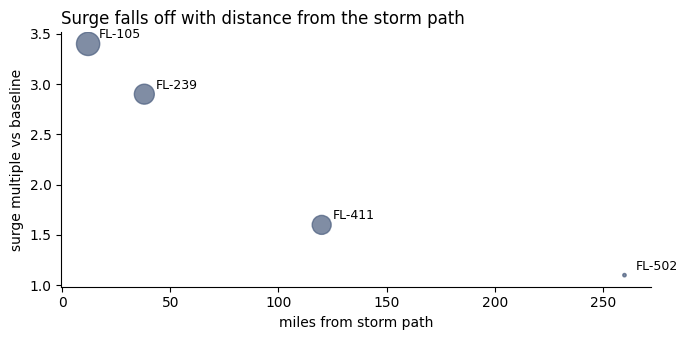

note the smallest bubble: FL-502 has only 90 transactions,
so its 1.1x is barely distinguishable from noise.


In [7]:
by_store = pd.DataFrame({
    'store_id': ['FL-105', 'FL-239', 'FL-411', 'FL-502'],
    'surge_multiple': [3.4, 2.9, 1.6, 1.1],
    'miles_from_path': [12, 38, 120, 260],
    'transactions': [4200, 3100, 2800, 90],
})

fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['transactions'] / 15
ax.scatter(by_store['miles_from_path'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge falls off with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm path')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('note the smallest bubble: FL-502 has only 90 transactions,')
print('so its 1.1x is barely distinguishable from noise.')

Sizing the points by transaction count is doing real work here — it tells the reader which points to trust. A four-point scatter is not a trend line, and you should say so out loud rather than fitting one.

**TODO:** build your version. If you only have a handful of stores, present it as a table with a comment instead of a scatter — a chart with five points and a regression line will get asked about.

storm center: 29.49N 83.97W, 945 hPa at 2024-09-27T02:00 GMT


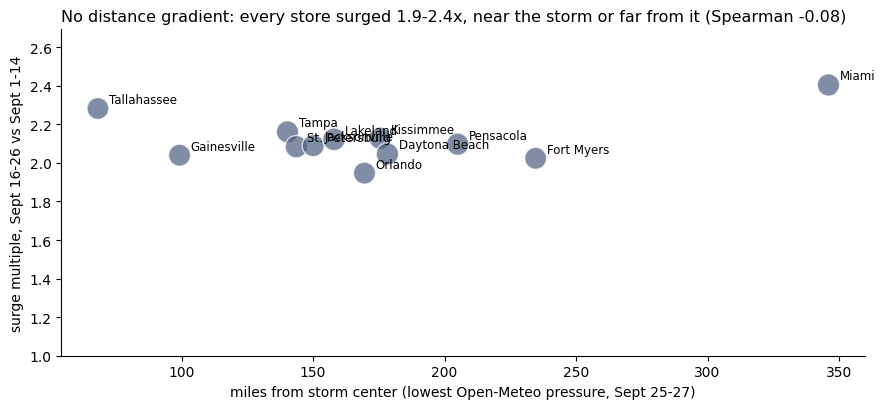

                    city  surge_multiple  miles_from_storm  transactions
store_id                                                                
FL-619       Tallahassee            2.28             68.16          1981
FL-078       Gainesville            2.04             99.21          2001
FL-105             Tampa            2.16            140.24          2043
FL-445    St. Petersburg            2.08            143.61          2074
FL-412      Jacksonville            2.09            150.05          2028
FL-302          Lakeland            2.12            157.95          2123
FL-239           Orlando            1.95            169.54          2010
FL-287         Kissimmee            2.13            175.48          2053
FL-156     Daytona Beach            2.05            178.26          2074
FL-710         Pensacola            2.10            204.99          2066
FL-501        Fort Myers            2.02            234.62          2002
FL-330             Miami            2.40           

In [9]:
# Pattern 4: surge multiple by store vs. distance from the storm center
# Storm center = lowest Open-Meteo sea-level pressure on a 0.5-degree grid, Sept 25-27 (same method as team notebook 7.1)
import requests
pts = [(la, lo) for la in np.arange(26.0, 31.01, 0.5) for lo in np.arange(-87.5, -80.99, 0.5)]
r = requests.get('https://archive-api.open-meteo.com/v1/archive', timeout=120, params={
    'latitude': ','.join(f'{la:.2f}' for la, _ in pts), 'longitude': ','.join(f'{lo:.2f}' for _, lo in pts),
    'start_date': '2024-09-25', 'end_date': '2024-09-27', 'hourly': 'pressure_msl', 'timezone': 'GMT'})
r.raise_for_status()
grid = pd.concat([pd.DataFrame(p['hourly']).assign(lat=p['latitude'], lon=p['longitude']) for p in r.json()], ignore_index=True).dropna()
center = grid.loc[grid['pressure_msl'].idxmin()]
STORM_LAT, STORM_LON = float(center['lat']), float(center['lon'])
print(f"storm center: {STORM_LAT:.2f}N {abs(STORM_LON):.2f}W, {center['pressure_msl']:.0f} hPa at {center['time']} GMT")

st = stores.assign(store_id=clean_store_id(stores['store_id'])).drop_duplicates('store_id').set_index('store_id')
st[['latitude', 'longitude']] = st[['latitude', 'longitude']].astype(float)
st.loc['FL-619', ['latitude', 'longitude']] = [30.43826, -84.28073]   # Tallahassee was blank; Open-Meteo geocoding (team notebook 1)

def miles(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 3958.8 * np.arcsin(np.sqrt(a))

store_daily = dated.groupby(['date', 'store_id'])['quantity'].sum().unstack()
by_store = pd.DataFrame({
    'city': st['city'],
    'surge_multiple': store_daily.loc[SURGE_START:SURGE_END].mean() / store_daily.loc[BASELINE_START:BASELINE_END].mean(),
    'miles_from_storm': miles(st['latitude'], st['longitude'], STORM_LAT, STORM_LON),
    'transactions': dated.groupby('store_id')['transaction_id'].nunique(),
}).sort_values('miles_from_storm')
rho = by_store['surge_multiple'].corr(by_store['miles_from_storm'], method='spearman')

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.scatter(by_store['miles_from_storm'], by_store['surge_multiple'], s=by_store['transactions'] / 8,
           alpha=0.7, color='#4a5d7e', edgecolor='white')
for row in by_store.itertuples():
    ax.annotate(row.city, (row.miles_from_storm, row.surge_multiple), textcoords='offset points', xytext=(8, 4), fontsize=8.5)
ax.set_ylim(1, by_store['surge_multiple'].max() * 1.12)
lo, hi = by_store['surge_multiple'].min(), by_store['surge_multiple'].max()
ax.set_title(f'No distance gradient: every store surged {lo:.1f}-{hi:.1f}x, near the storm or far from it (Spearman {rho:+.2f})',
             loc='left', fontsize=11.5)
ax.set_xlabel('miles from storm center (lowest Open-Meteo pressure, Sept 25-27)')
ax.set_ylabel('surge multiple, Sept 16-26 vs Sept 1-14')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()
print(by_store.round(2).to_string())
print(f'\nBubble size = transactions; the smallest store still has {by_store["transactions"].min():,}, so no point is noise.')
print('12 points with no visible gradient, so no trend line: the surge was statewide, not distance-driven.')


### Before you leave

- At least two presentation-ready charts, each with a message title
- Q1 has a stated baseline window and a multiple
- Q2 has a before-and-after comparison
- Everything pushed

Monday is presentations. The timing breakdown and the self-check are in Monday's notebook — read it tonight, not Monday morning.

---

## Checkpoint (participation)

Report the surge multiple you found for your top product and the baseline window you used to get it.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [10]:
# Checkpoint
top_product = 'Pop-Tarts Strawberry'   # biggest mover, after consolidating its 4 SKUs (PT-12, SKU#459812, POPTART-STRAW, PT_STRAWBERRY)
surge_multiple = 4.2                    # Sept 16-26 surge window vs baseline (+321%); 8.4x at the Sept 24-25 peak
baseline_window = '14 days, Sept 1-14, 2024 (ends 12 days before the storm arrived Sept 26)'
charts_ready = 4                        # Patterns 1-4 above, each with a message title

print('top product:', top_product)
print('surge multiple:', surge_multiple)
print('baseline window:', baseline_window)
print('charts ready:', charts_ready)


top product: Pop-Tarts Strawberry
surge multiple: 4.2
baseline window: 14 days, Sept 1-14, 2024 (ends 12 days before the storm arrived Sept 26)
charts ready: 4
